# Citi Bike NYC · Demanda, clima, rebalanceo y expansión de estaciones

**Marco PACE.** El equipo de producto necesita decidir **dónde crecer** y **cómo operar mejor** la red.
Preguntas de negocio:

1. ¿Cuánto influyen el clima y el día de la semana en la demanda, y es igual para abonados y ocasionales?
2. ¿Cómo usan el sistema los distintos tipos de usuario?
3. ¿Qué estaciones se vacían o se llenan, a qué hora y cuántas bicicletas hay que mover?
4. ¿En qué barrios conviene abrir o densificar estaciones?

**Datos:** 24,3 millones de viajes de 2016-2017 procesados en **BigQuery** (`sql/01_construir_modelo.sql`),
clima diario de NOAA (estación Central Park) y límites postales del Censo de EE. UU.
Este notebook trabaja sobre las tablas agregadas que se exportaron (`data/bigquery/`), enriquecidas por
`src/preparar_datos.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BQ, TB, IMG = ROOT / "data" / "bigquery", ROOT / "data" / "tableau", ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#1f9e6e", "#b8b6ae", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c7bf",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e7e5df",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 10.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
def guardar(fig, nombre): fig.savefig(IMG / f"{nombre}.png"); plt.show()

dem = pd.read_csv(TB / "demanda_diaria_clima.csv", parse_dates=["fecha"])
reb = pd.read_csv(TB / "rebalanceo_estaciones.csv")
bar = pd.read_csv(TB / "expansion_barrios.csv")
flu = pd.read_csv(TB / "flujo_horario.csv")
per = pd.read_csv(TB / "perfil_usuarios.csv")
rut = pd.read_csv(TB / "rutas_top.csv")
edad = pd.read_csv(TB / "abonados_edad_genero.csv")
cal = pd.read_csv(BQ / "calidad_datos.csv")

## 1. Calidad y cobertura de los datos

In [2]:
c = cal.iloc[0]
excluidos = c.mas_de_3_horas + c.coordenadas_fuera_de_nyc
print(f"Viajes brutos 2016-2017:          {c.viajes_brutos:>12,}")
print(f"Más de 3 horas (no devueltas):   {c.mas_de_3_horas:>12,}")
print(f"Coordenadas fuera de NYC:         {c.coordenadas_fuera_de_nyc:>12,}  (estaciones de prueba/taller)")
LIMPIOS = 24_325_562   # COUNT(*) de viajes_limpios en BigQuery (las reglas se superponen, por eso no es una resta)
print(f"Viajes limpios:                   {LIMPIOS:>12,}  ({1 - LIMPIOS / c.viajes_brutos:.2%} excluido)")
print(f"Año de nacimiento < 1930 (anulado, no excluido): {c.anio_nacimiento_improbable:,}")

Viajes brutos 2016-2017:            24,381,318
Más de 3 horas (no devueltas):         55,589
Coordenadas fuera de NYC:                  221  (estaciones de prueba/taller)
Viajes limpios:                     24,325,562  (0.23% excluido)
Año de nacimiento < 1930 (anulado, no excluido): 11,900


In [3]:
cobertura = dem.groupby(dem.fecha.dt.to_period("M")).fecha.nunique()
todos = pd.period_range("2016-01", "2017-12", freq="M")
faltan = [str(p) for p in todos if p not in cobertura.index]
print("Meses sin datos en la tabla pública:", ", ".join(faltan))
ene = dem[dem.fecha.dt.to_period("M") == "2016-01"].fecha.dt.day
print("Días faltantes en enero 2016:", sorted(set(range(1, 32)) - set(ene)))

Meses sin datos en la tabla pública: 2016-10, 2016-11, 2016-12, 2017-01, 2017-02, 2017-03
Días faltantes en enero 2016: [23, 24, 25, 26]


**Hallazgo de calidad:** la tabla pública `citibike_trips` **no tiene datos de octubre 2016 a marzo 2017**
(6 meses), y faltan del 23 al 26 de enero de 2016, cuando el sistema cerró por la tormenta de nieve Jonas.
Consecuencias para el análisis:
- El crecimiento interanual se mide solo con **abril-septiembre**, meses presentes en ambos años.
- Los indicadores por estación se calculan **por día de operación**, no por año calendario.

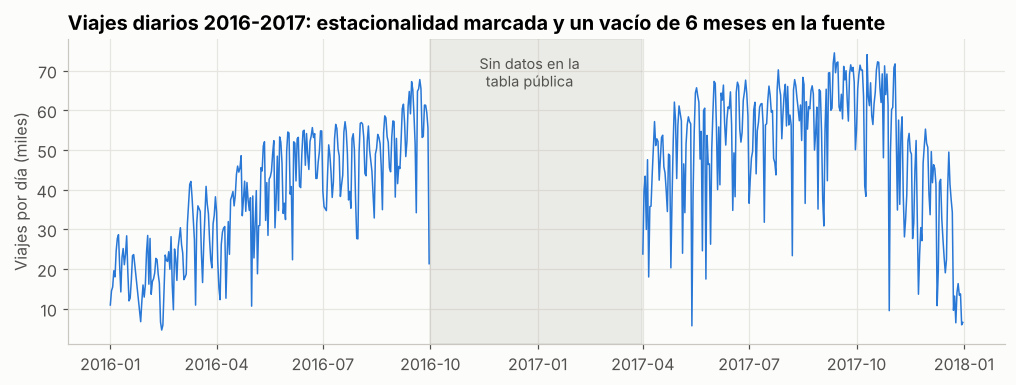

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for anio, g in dem.groupby("anio"):
    ax.plot(g.fecha, g.viajes / 1000, color=AZUL, lw=1)
ax.axvspan(pd.Timestamp("2016-10-01"), pd.Timestamp("2017-03-31"), color=GRIS, alpha=0.25)
ax.text(pd.Timestamp("2016-12-25"), 66, "Sin datos en la\ntabla pública", ha="center", color=TINTA2, fontsize=9.5)
ax.set_title("Viajes diarios 2016-2017: estacionalidad marcada y un vacío de 6 meses en la fuente")
ax.set_ylabel("Viajes por día (miles)")
guardar(fig, "01_demanda_diaria")

In [5]:
comp = dem[dem.mes.between(4, 9)].groupby("anio")[["Abonado", "Ocasional", "viajes"]].sum()
crec = (comp.loc[2017] / comp.loc[2016] - 1)
print("Crecimiento abril-septiembre 2017 vs 2016:"); print(crec.map("{:+.1%}".format).to_string())

Crecimiento abril-septiembre 2017 vs 2016:
Abonado      +20.5%
Ocasional    +23.9%
viajes       +20.9%


## 2. Clima y día de la semana

Modelo de regresión sobre el **logaritmo de los viajes diarios**, así cada coeficiente se lee como
% de cambio. Controla temperatura máxima (con término cuadrático), tramo de lluvia, nieve, fin de semana y año.
Errores estándar robustos (HC3). Se estima por separado para abonados y ocasionales.

In [6]:
dem["finde"] = dem.es_fin_de_semana.astype(int)
formula = "np.log({y}) ~ temp_max_c + I(temp_max_c**2) + C(tramo_lluvia, Treatment('Sin lluvia')) + hubo_nieve + finde + C(anio)"
modelos = {y: smf.ols(formula.format(y=y), data=dem).fit(cov_type="HC3") for y in ["viajes", "Abonado", "Ocasional"]}
nombres = {"C(tramo_lluvia, Treatment('Sin lluvia'))[T.Lluvia leve (<5 mm)]": "Lluvia leve (<5 mm)",
           "C(tramo_lluvia, Treatment('Sin lluvia'))[T.Moderada (5-15 mm)]": "Lluvia moderada (5-15 mm)",
           "C(tramo_lluvia, Treatment('Sin lluvia'))[T.Fuerte (>15 mm)]": "Lluvia fuerte (>15 mm)",
           "hubo_nieve[T.True]": "Nieve", "finde": "Fin de semana"}
efectos = pd.DataFrame({y: (np.exp(m.params[list(nombres)]) - 1) * 100 for y, m in modelos.items()}).rename(index=nombres)
pvals = pd.DataFrame({y: m.pvalues[list(nombres)] for y, m in modelos.items()}).rename(index=nombres)
print({y: round(m.rsquared, 3) for y, m in modelos.items()})
efectos.round(1).astype(str) + " %"

{'viajes': np.float64(0.693), 'Abonado': np.float64(0.688), 'Ocasional': np.float64(0.752)}


,viajes,Abonado,Ocasional
Lluvia leve (<5 mm),-11.7 %,-11.7 %,-12.8 %
Lluvia moderada (5-15 mm),-11.4 %,-10.8 %,-14.5 %
Lluvia fuerte (>15 mm),-11.7 %,-11.1 %,-24.1 %
Nieve,-16.0 %,-15.5 %,-33.8 %
Fin de semana,-21.1 %,-32.4 %,119.5 %


In [7]:
pvals.round(4)

,viajes,Abonado,Ocasional
Lluvia leve (<5 mm),0.00,0.00,0.03
Lluvia moderada (5-15 mm),0.02,0.03,0.08
Lluvia fuerte (>15 mm),0.00,0.00,0.00
Nieve,0.09,0.12,0.00
Fin de semana,0.00,0.00,0.00


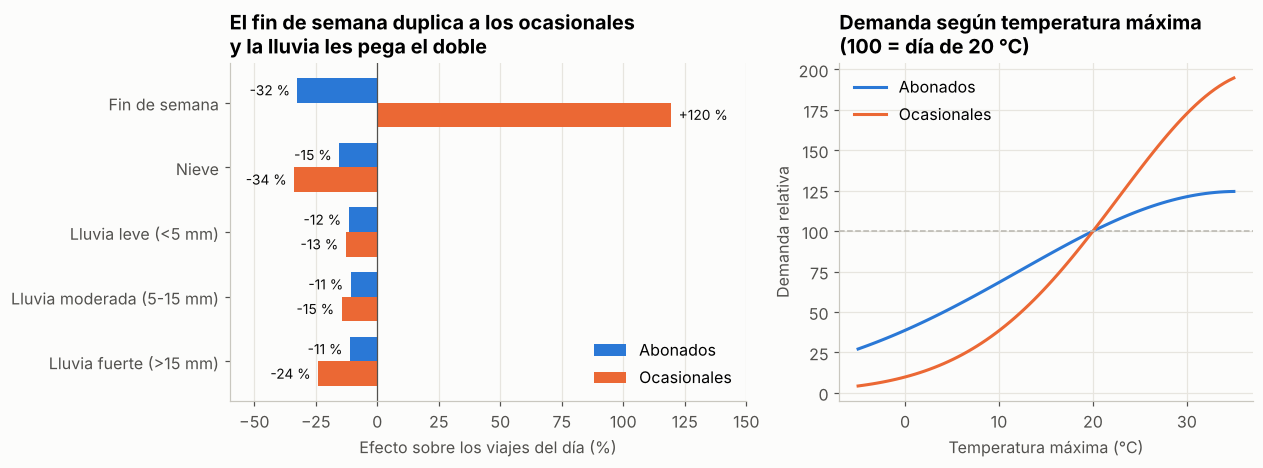

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
orden = ["Fin de semana", "Nieve", "Lluvia leve (<5 mm)", "Lluvia moderada (5-15 mm)", "Lluvia fuerte (>15 mm)"]
y = np.arange(len(orden)); h = 0.38
ax.barh(y - h/2, efectos.loc[orden, "Abonado"], h, color=AZUL, label="Abonados")
ax.barh(y + h/2, efectos.loc[orden, "Ocasional"], h, color=NARANJA, label="Ocasionales")
ax.set_yticks(y, orden); ax.invert_yaxis(); ax.axvline(0, color=TINTA2, lw=0.8)
for i, k in enumerate(orden):
    for dy, col in [(-h/2, "Abonado"), (h/2, "Ocasional")]:
        v = efectos.loc[k, col]
        ax.text(v + (3 if v >= 0 else -3), i + dy, f"{v:+.0f} %", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=TINTA)
ax.set_xlim(-60, 150); ax.set_xlabel("Efecto sobre los viajes del día (%)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("El fin de semana duplica a los ocasionales\ny la lluvia les pega el doble")
ax = axes[1]
t = np.linspace(-5, 35, 80)
for y_, col, lab in [("Abonado", AZUL, "Abonados"), ("Ocasional", NARANJA, "Ocasionales")]:
    m = modelos[y_]; b1, b2 = m.params["temp_max_c"], m.params["I(temp_max_c ** 2)"]
    rel = np.exp(b1 * t + b2 * t**2 - (b1 * 20 + b2 * 400)) * 100
    ax.plot(t, rel, color=col, lw=2, label=lab)
ax.axhline(100, color=GRIS, lw=1, ls="--")
ax.set_title("Demanda según temperatura máxima\n(100 = día de 20 °C)"); ax.set_xlabel("Temperatura máxima (°C)")
ax.set_ylabel("Demanda relativa"); ax.legend(frameon=False)
guardar(fig, "02_clima_y_dia")

In [9]:
for y_ in ["Abonado", "Ocasional"]:
    m = modelos[y_]; b1, b2 = m.params["temp_max_c"], m.params["I(temp_max_c ** 2)"]
    print(f"{y_:10s} un día de 25 °C vs uno de 5 °C: {np.exp(b1*25 + b2*625 - b1*5 - b2*25) - 1:+.0%}")

Abonado    un día de 25 °C vs uno de 5 °C: +114%
Ocasional  un día de 25 °C vs uno de 5 °C: +576%


**Lectura:**
- **Abonados:** usan la bicicleta para ir a trabajar. Caen un tercio el fin de semana (−32 %) y son menos
  sensibles al clima: llueva poco o mucho, bajan alrededor de 11 %.
- **Ocasionales:** usan la bicicleta para pasear. Se duplican con creces el fin de semana (+120 %), la lluvia fuerte
  los reduce 24 % y la nieve 34 %. Un día de 25 °C tiene casi 7 veces más ocasionales que uno de 5 °C
  (los abonados, 2 veces).
- La nieve no es significativa para los abonados (p = 0,12): con pocos días de nieve en la muestra, el efecto es incierto.
- El modelo explica cerca del 70 % de la variación diaria; el resto son feriados, eventos y factores no medidos.

## 3. Cómo usan el sistema abonados y ocasionales (2017)

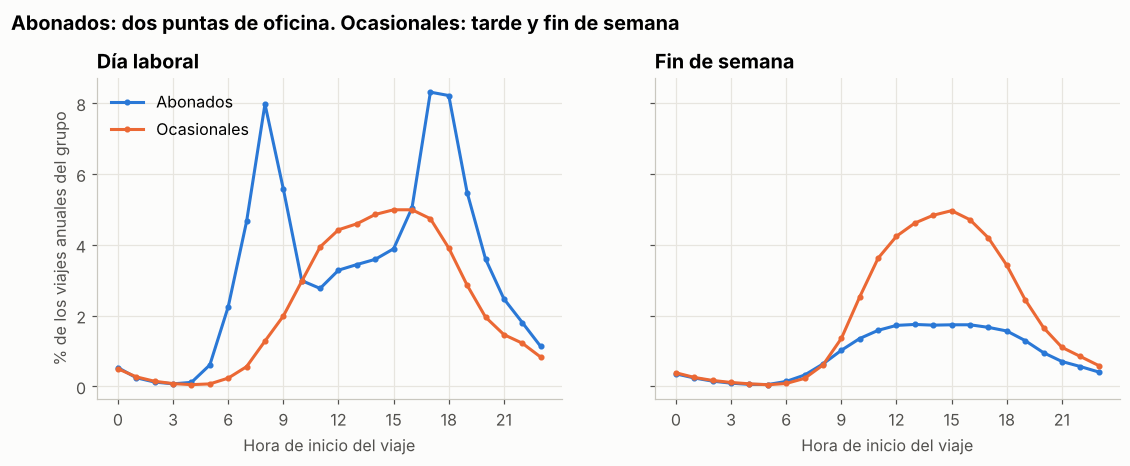

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, dia in zip(axes, ["Día laboral", "Fin de semana"]):
    for tipo, col, lab in [("Abonado", AZUL, "Abonados"), ("Ocasional", NARANJA, "Ocasionales")]:
        g = per[(per.tipo_usuario == tipo) & (per.tipo_dia == dia)].sort_values("hora")
        tot = per[per.tipo_usuario == tipo].viajes.sum()
        ax.plot(g.hora, g.viajes / tot * 100, color=col, lw=2, marker="o", ms=3, label=lab)
    ax.set_title(dia); ax.set_xlabel("Hora de inicio del viaje"); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("% de los viajes anuales del grupo"); axes[0].legend(frameon=False)
fig.suptitle("Abonados: dos puntas de oficina. Ocasionales: tarde y fin de semana", x=0.06, y=1.04, ha="left", fontweight="bold", fontsize=13)
guardar(fig, "03_perfil_horario")

In [11]:
res = per.groupby("tipo_usuario").apply(lambda g: pd.Series({
    "viajes_2017": g.viajes.sum(),
    "pct_fin_de_semana": g.loc[g.tipo_dia == "Fin de semana", "viajes"].sum() / g.viajes.sum(),
    "duracion_mediana_min": np.average(g.duracion_mediana_min, weights=g.viajes),
    "pct_ida_y_vuelta": np.average(g.pct_ida_y_vuelta, weights=g.viajes)}), include_groups=False)
res

,viajes_2017,pct_fin_de_semana,duracion_mediana_min,pct_ida_y_vuelta
tipo_usuario,,,,
Abonado,"12,431,316.00",0.22,9.70,0.01
Ocasional,"1,658,602.00",0.47,21.26,0.06


In [12]:
e = edad.groupby("genero").viajes.sum(); print((e / e.sum()).map("{:.1%}".format).to_string())
t = edad.groupby("tramo_edad").viajes.sum(); print((t / t.sum()).map("{:.1%}".format).to_string())

genero
Hombre      74.2%
Mujer       25.4%
Sin dato     0.4%
tramo_edad
1. Menos de 25     8.2%
2. 25-34          39.6%
3. 35-44          24.2%
4. 45-54          16.9%
5. 55-64           9.1%
6. 65 o más        2.0%


**Lectura:** el abonado típico hace viajes cortos (≈ 9 min) de casa al trabajo. El ocasional pedalea más del
doble de tiempo (≈ 21 min), y 6 % de sus viajes vuelven a la misma estación: recorridos de paseo.
Entre los abonados hay una brecha de género marcada: solo 1 de cada 4 viajes lo hace una mujer.

## 4. Rebalanceo: qué estaciones se vacían o se llenan

Para cada estación se acumula, hora a hora, el **flujo neto promedio** de un día laboral de 2017
(llegadas − salidas). La **amplitud** (punto más lleno − punto más vacío del día) es la cantidad de
bicicletas que el operador debe mover o de anclajes libres que la estación necesita para no colapsar.

In [13]:
tot = reb.amplitud_rebalanceo.sum()
n50 = (reb.pct_acumulado_necesidad <= 0.5).sum()
print(f"Necesidad diaria total de rebalanceo: {tot:,.0f} bicicletas en {len(reb)} estaciones")
print(f"El {n50 / len(reb):.0%} de las estaciones ({n50}) concentra el 50 % de la necesidad")
reb.perfil.value_counts()

Necesidad diaria total de rebalanceo: 10,436 bicicletas en 813 estaciones
El 17% de las estaciones (135) concentra el 50 % de la necesidad


perfil
Equilibrada                        650
Se llena en la mañana (destino)     88
Se vacía en la mañana (origen)      75
Name: count, dtype: int64

In [14]:
reb.head(10)[["ranking", "nombre", "barrio", "salidas_dia", "flujo_neto_punta_am", "flujo_neto_punta_pm", "amplitud_rebalanceo", "perfil"]]

,ranking,nombre,barrio,salidas_dia,flujo_neto_punta_am,flujo_neto_punta_pm,amplitud_rebalanceo,perfil
0,1,W 52 St & 6 Ave,Chelsea and Clinton,232.45,148.12,-106.18,179.30,Se llena en la mañana (destino)
1,2,Broadway & E 22 St,Gramercy Park and Murray Hill,394.58,121.86,-110.72,160.30,Se llena en la mañana (destino)
2,3,8 Ave & W 31 St,Chelsea and Clinton,375.26,-56.38,69.79,140.80,Se vacía en la mañana (origen)
3,4,E 7 St & Avenue A,Lower East Side,229.02,-72.13,65.16,136.80,Se vacía en la mañana (origen)
4,5,Grand Army Plaza & Central Park S,Chelsea and Clinton,273.42,100.29,-75.03,135.70,Se llena en la mañana (destino)
5,6,E 47 St & Park Ave,Gramercy Park and Murray Hill,263.90,111.71,-89.59,123.90,Se llena en la mañana (destino)
6,7,Broadway & Battery Pl,Lower Manhattan,174.37,79.76,-52.33,104.80,Se llena en la mañana (destino)
7,8,W 42 St & Dyer Ave,Chelsea and Clinton,160.95,-42.39,49.19,90.20,Se vacía en la mañana (origen)
8,9,6 Ave & Canal St,Greenwich Village and Soho,157.71,65.10,-62.13,87.60,Se llena en la mañana (destino)
9,10,E 55 St & 3 Ave,Gramercy Park and Murray Hill,150.62,65.06,-59.44,75.40,Se llena en la mañana (destino)


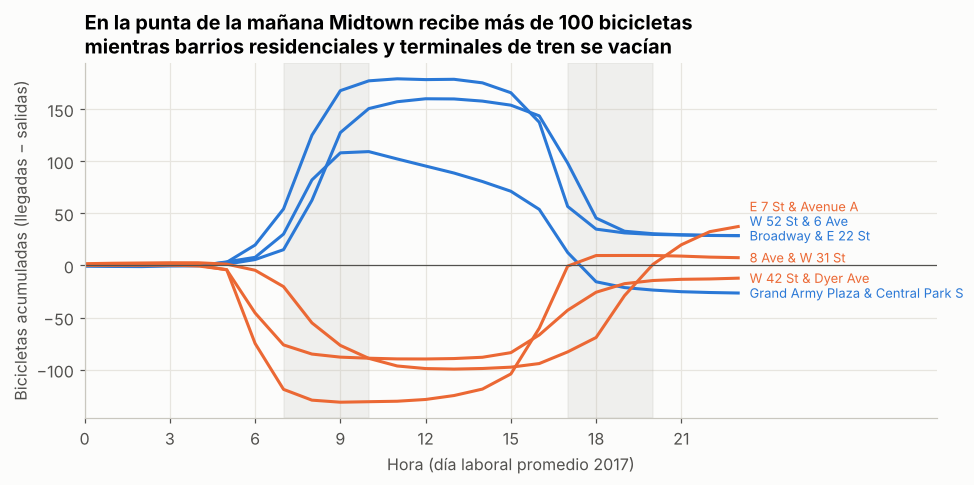

In [15]:
w = flu[flu.tipo_dia == "Día laboral"].sort_values(["station_id", "hora"]).copy()
w["acum"] = w.groupby("station_id").flujo_neto_prom_dia.cumsum()
llenan = reb[reb.perfil.str.startswith("Se llena")].head(3).station_id
vacian = reb[reb.perfil.str.startswith("Se vacía")].head(3).station_id
fig, ax = plt.subplots(figsize=(10, 4.2))
etiquetas = []
for ids, col in [(llenan, AZUL), (vacian, NARANJA)]:
    for sid in ids:
        g = w[w.station_id == sid]
        ax.plot(g.hora, g.acum, color=col, lw=2)
        etiquetas.append([g.acum.iloc[-1], g.nombre.iloc[0], col])
etiquetas.sort(key=lambda e: e[0])
for i in range(1, len(etiquetas)):                      # separa etiquetas que se tocan
    etiquetas[i][0] = max(etiquetas[i][0], etiquetas[i - 1][0] + 14)
for yv, nombre, col in etiquetas:
    ax.text(23.4, yv, nombre, va="center", fontsize=8.5, color=col)
ax.axhline(0, color=TINTA2, lw=0.8)
ax.axvspan(7, 10, color=GRIS, alpha=0.18); ax.axvspan(17, 20, color=GRIS, alpha=0.18)
ax.set_xlim(0, 30); ax.set_xticks(range(0, 24, 3))
ax.set_title("En la punta de la mañana Midtown recibe más de 100 bicicletas\nmientras barrios residenciales y terminales de tren se vacían")
ax.set_xlabel("Hora (día laboral promedio 2017)"); ax.set_ylabel("Bicicletas acumuladas (llegadas − salidas)")
guardar(fig, "04_rebalanceo_curvas")

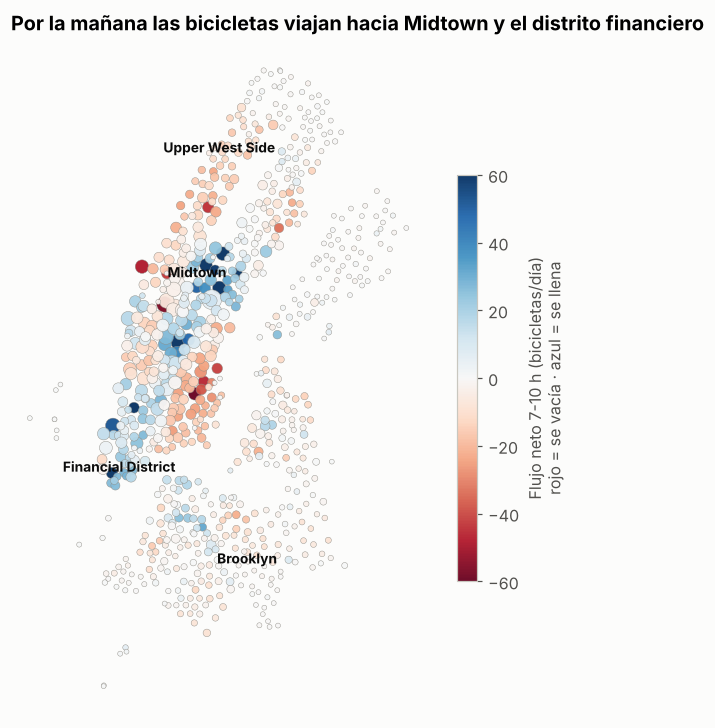

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 8))
r = reb.dropna(subset=["flujo_neto_punta_am"]).copy()
v = r.flujo_neto_punta_am.clip(-60, 60)
sc = ax.scatter(r.lng, r.lat, c=v, cmap="RdBu", vmin=-60, vmax=60, s=10 + r.salidas_dia / 4, edgecolor="#8f8d86", linewidth=0.3, alpha=0.95)
cb = fig.colorbar(sc, ax=ax, shrink=0.6); cb.set_label("Flujo neto 7-10 h (bicicletas/día)\nrojo = se vacía · azul = se llena")
ax.set_aspect(1 / np.cos(np.radians(40.73))); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Por la mañana las bicicletas viajan hacia Midtown y el distrito financiero")
for txt, x, y in [("Midtown", -73.983, 40.758), ("Financial District", -74.011, 40.705), ("Brooklyn", -73.965, 40.680), ("Upper West Side", -73.975, 40.792)]:
    ax.text(x, y, txt, fontsize=9, color=TINTA, ha="center", fontweight="bold")
guardar(fig, "05_mapa_flujo_manana")

## 5. Expansión: dónde abrir o densificar estaciones

Puntaje 0-100 por barrio (≥ 2 estaciones en 2017), con pesos explícitos:
- **50 % saturación:** salidas por estación por día de operación en 2017.
- **30 % crecimiento:** cuánto más creció la carga por estación del barrio que la del sistema.
- **20 % presión de rebalanceo:** amplitud promedio por estación.

Se usan rangos percentiles para que ninguna escala domine.

In [17]:
bar[["barrio", "distrito", "estaciones_2017", "carga_por_estacion_2017", "indice_crecimiento", "rebalanceo_prom_estacion", "puntaje_expansion", "recomendacion"]]

,barrio,distrito,estaciones_2017,carga_por_estacion_2017,indice_crecimiento,rebalanceo_prom_estacion,puntaje_expansion,recomendacion
0,Chelsea and Clinton,Manhattan,82.00,153.51,1.17,26.30,81.00,Prioridad alta: densificar
1,Tribeca,Manhattan,2.00,273.71,1.13,45.50,81.00,Prioridad alta: densificar
2,Gramercy Park and Murray Hill,Manhattan,49.00,141.03,1.23,27.93,79.00,Prioridad alta: densificar
3,Greenwich Village and Soho,Manhattan,40.00,145.65,1.19,19.78,77.00,Prioridad alta: densificar
4,Lower East Side,Manhattan,67.00,118.68,1.15,23.61,67.00,Prioridad media: monitorear
5,Greenpoint,Brooklyn,54.00,49.07,1.46,8.90,62.00,Prioridad media: monitorear
6,Lower Manhattan,Manhattan,36.00,91.75,1.11,19.32,58.00,Prioridad media: monitorear
7,Northwest Brooklyn,Brooklyn,139.00,35.65,1.27,8.48,54.00,Prioridad media: monitorear
8,Upper West Side,Manhattan,53.00,81.41,1.10,16.27,52.00,Prioridad media: monitorear
9,Central Harlem,Manhattan,22.00,21.30,NaN,2.01,50.00,Prioridad media: monitorear


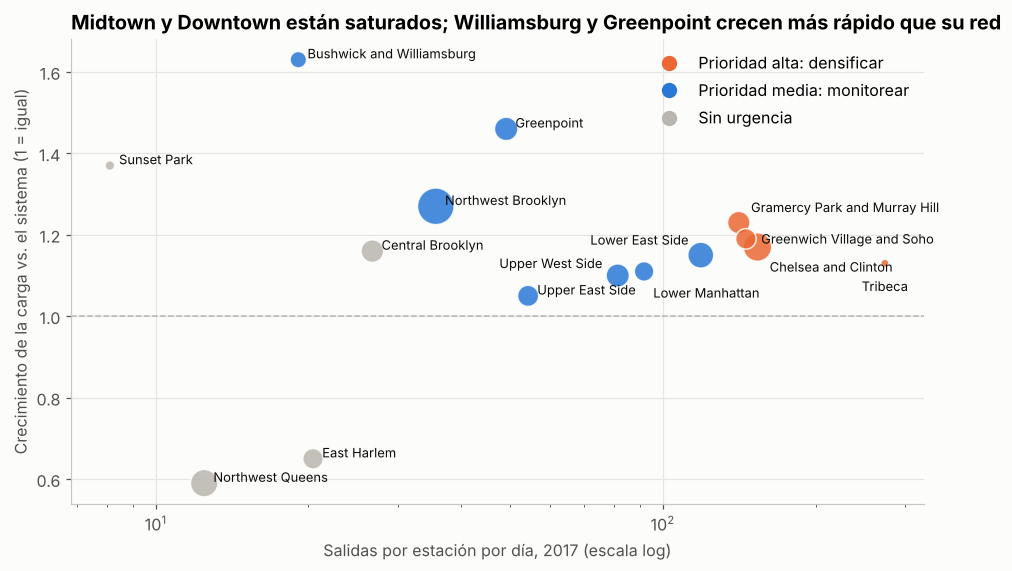

In [18]:
b = bar.dropna(subset=["indice_crecimiento"])
fig, ax = plt.subplots(figsize=(10, 5.5))
col = b.recomendacion.map({"Prioridad alta: densificar": NARANJA, "Prioridad media: monitorear": AZUL, "Sin urgencia": GRIS})
ax.scatter(b.carga_por_estacion_2017, b.indice_crecimiento, s=b.estaciones_2017 * 4 + 20, c=col, alpha=0.85, edgecolor="white", lw=1)
desplaz = {"Gramercy Park and Murray Hill": (8, 10), "Greenwich Village and Soho": (10, 0), "Chelsea and Clinton": (8, -13),
           "Lower East Side": (-8, 10), "Lower Manhattan": (6, -14), "Upper West Side": (-10, 8), "Tribeca": (0, -15)}
for _, r in b.iterrows():
    dx, dy = desplaz.get(r.barrio, (6, 4))
    ax.annotate(r.barrio, (r.carga_por_estacion_2017, r.indice_crecimiento), xytext=(dx, dy), textcoords="offset points",
                fontsize=8.5, color=TINTA, ha="right" if dx < 0 else ("center" if dx == 0 else "left"), va="center")
ax.axhline(1, color=GRIS, ls="--", lw=1); ax.set_xscale("log")
ax.set_xlabel("Salidas por estación por día, 2017 (escala log)"); ax.set_ylabel("Crecimiento de la carga vs. el sistema (1 = igual)")
ax.set_title("Midtown y Downtown están saturados; Williamsburg y Greenpoint crecen más rápido que su red")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=l, ms=9) for l, c in
                   [("Prioridad alta: densificar", NARANJA), ("Prioridad media: monitorear", AZUL), ("Sin urgencia", GRIS)]],
          frameon=False, loc="upper right")
guardar(fig, "06_expansion_barrios")

## 6. Rutas más usadas

In [19]:
for tipo in ["Abonado", "Ocasional"]:
    g = rut[rut.tipo_usuario == tipo].head(5)
    print(f"\n{ {'Abonado': 'Abonados', 'Ocasional': 'Ocasionales'}[tipo] }: top 5 rutas 2017")
    print(g[["estacion_origen", "estacion_destino", "viajes", "duracion_mediana_min", "distancia_km"]].to_string(index=False))
print("\n% de ida y vuelta en el top 300:", rut.groupby("tipo_usuario").es_ida_y_vuelta.mean().map("{:.0%}".format).to_dict())


Abonados: top 5 rutas 2017
       estacion_origen       estacion_destino  viajes  duracion_mediana_min  distancia_km
     E 7 St & Avenue A Cooper Square & E 7 St    6513                  4.20          0.68
       W 21 St & 6 Ave        9 Ave & W 22 St    3854                  4.30          0.78
 Pershing Square North     Broadway & W 32 St    3646                  6.70          0.95
Cooper Square & E 7 St      E 7 St & Avenue A    3545                  4.40          0.68
 Pershing Square North   E 24 St & Park Ave S    3515                  6.50          1.40

Ocasionales: top 5 rutas 2017
                  estacion_origen                  estacion_destino  viajes  duracion_mediana_min  distancia_km
           Central Park S & 6 Ave                   5 Ave & E 88 St    5201                 22.60          2.38
           Central Park S & 6 Ave            Central Park S & 6 Ave    4909                 35.00          0.00
Grand Army Plaza & Central Park S Grand Army Plaza & Central Park

## 7. Conclusiones y recomendaciones

| Pregunta | Hallazgo | Recomendación |
| --- | --- | --- |
| Clima y día | La lluvia reduce los viajes ~12 %; los ocasionales caen 24 % con lluvia fuerte y se duplican el fin de semana | Ajustar la flota y el personal de rebalanceo según el pronóstico; promociones para ocasionales en días soleados de fin de semana |
| Usuarios | Abonados: viajes de 9-10 min en las puntas de oficina. Ocasionales: 21 min, tarde y fin de semana, 6 % ida y vuelta | Convertir ocasionales frecuentes en abonados con pases de fin de semana; campañas para cerrar la brecha de género (74 % de los viajes de abonados son de hombres) |
| Rebalanceo | 17 % de las estaciones concentra el 50 % de la necesidad diaria (~10.400 bicicletas de amplitud total) | Concentrar camiones y *valet* de anclajes en las ~135 estaciones críticas; reponer los orígenes (barrios residenciales y terminales como Penn Station) antes de las 7:00 y vaciar Midtown antes de la punta de la tarde |
| Expansión | Chelsea, Gramercy, Greenwich Village y Tribeca están saturados; Williamsburg y Greenpoint crecen más rápido que su red | Densificar Manhattan bajo la calle 59 con más anclajes por estación; ampliar la red en Williamsburg y Greenpoint |

**Limitaciones:** la tabla pública no tiene datos de octubre 2016 a marzo 2017; el crecimiento se mide solo con
abril-septiembre. No hay capacidad de anclajes por estación en este período, así que la saturación se mide por demanda,
no por ocupación. Los efectos del clima son asociaciones observacionales.